epoch: 1; G_loss: 0.597937; D_loss: 1.652549
epoch: 500; G_loss: 0.880883; D_loss: 1.722074
epoch: 1000; G_loss: 0.733832; D_loss: 1.355415
epoch: 1500; G_loss: 0.710609; D_loss: 1.356593
epoch: 2000; G_loss: 0.710368; D_loss: 1.371069


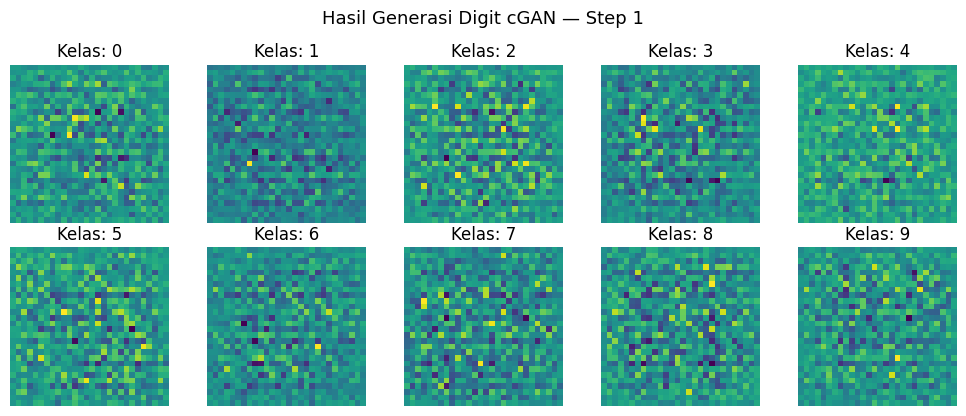

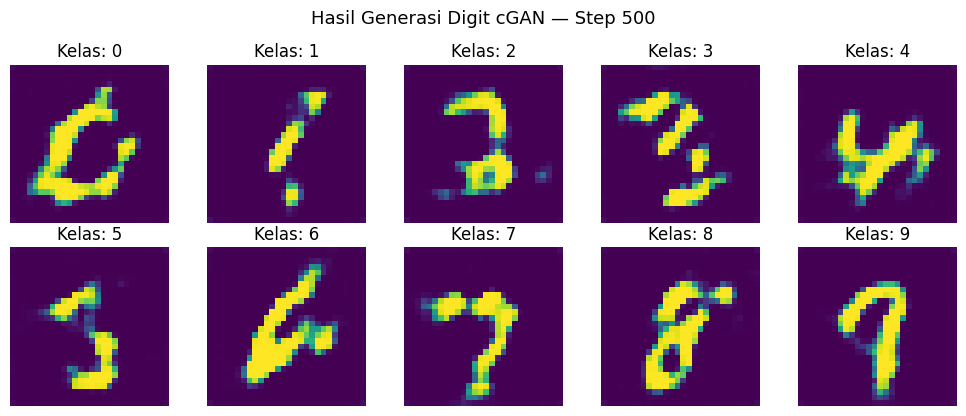

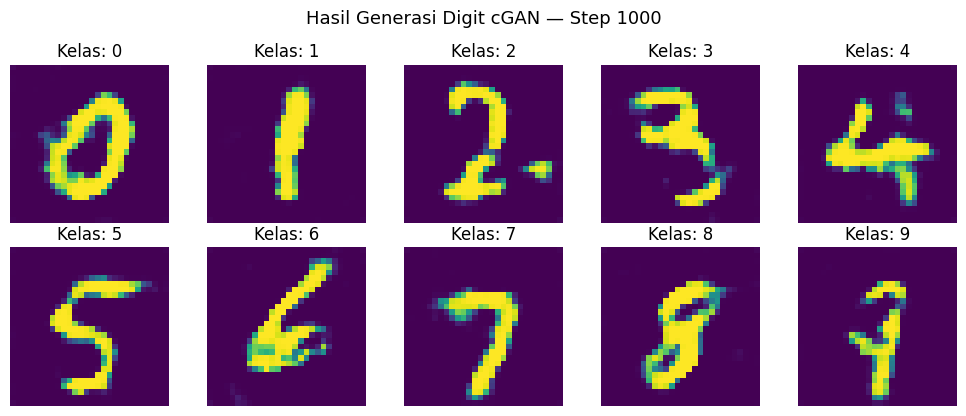

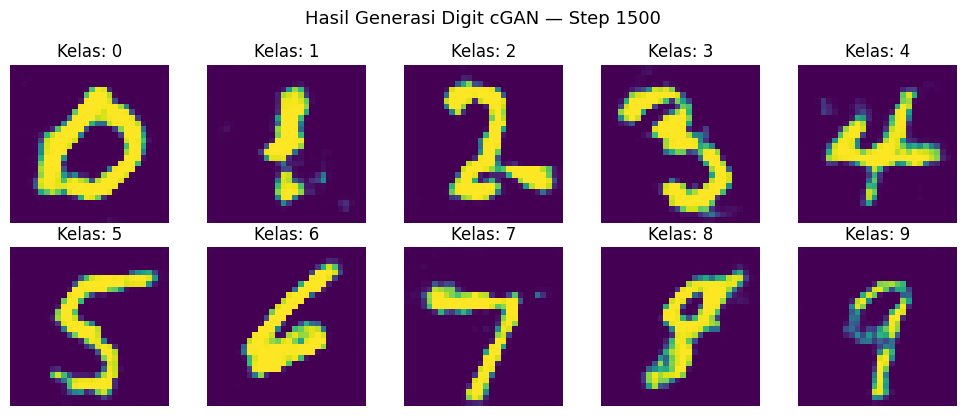

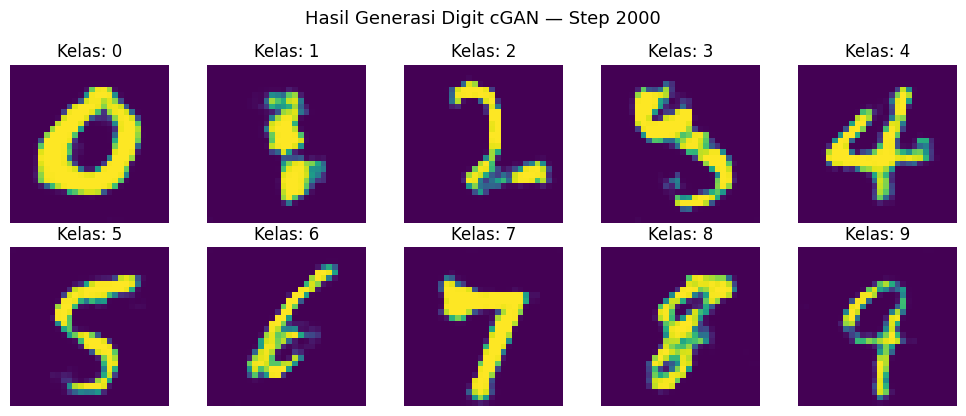

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Hyperparameter
batch_size = 200
steps = 2000
z_dim = 100

# Noise tetap dan label kelas one-hot (0 hingga 9) untuk visualisasi
tf.random.set_seed(42)
z_vis = tf.random.normal([10, z_dim])
y_vis = tf.constant(np.eye(10), dtype="float32")

# Memuat dan menormalisasi dataset MNIST
(x_train, y_train), _ = tf.keras.datasets.mnist.load_data()
x_train = (x_train / 255.0).astype("float32")
y_train = tf.one_hot(y_train, depth=10, dtype="float32")

dataset = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(4 * batch_size)
    .batch(batch_size)
    .repeat()
)
data_iter = iter(dataset)

# Generator (arsitektur sama dengan shinyflight/cGAN.py)
def Generator():
    z = tf.keras.layers.Input(shape=(z_dim,), dtype="float32")
    y = tf.keras.layers.Input(shape=(10,), dtype="float32")

    x = tf.keras.layers.Concatenate()([z, y])
    x = tf.keras.layers.Dense(3 * 3 * 512)(x)
    x = tf.keras.layers.Reshape((3, 3, 512))(x)

    x = tf.keras.layers.Conv2DTranspose(256, 3, strides=2, padding="valid")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.LeakyReLU()(x)

    x = tf.keras.layers.Conv2DTranspose(128, 4, strides=2, padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.LeakyReLU()(x)

    x = tf.keras.layers.Conv2DTranspose(1, 4, strides=2, padding="same", activation="sigmoid")(x)
    out = tf.keras.layers.Reshape((28, 28))(x)

    return tf.keras.Model(inputs=[z, y], outputs=out)

# Discriminator (arsitektur sama dengan shinyflight/cGAN.py)
def Discriminator():
    X = tf.keras.layers.Input(shape=(28, 28), dtype="float32")
    Y = tf.keras.layers.Input(shape=(10,), dtype="float32")

    y = tf.keras.layers.Reshape((1, 1, 10))(Y)
    y = tf.keras.layers.UpSampling2D(size=(28, 28))(y)
    x = tf.keras.layers.Reshape((28, 28, 1))(X)
    x = tf.keras.layers.Concatenate()([x, y])

    x = tf.keras.layers.Conv2D(128, 4, strides=2, padding="same")(x)
    x = tf.keras.layers.LeakyReLU()(x)

    x = tf.keras.layers.Conv2D(256, 4, strides=2, padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.LeakyReLU()(x)

    x = tf.keras.layers.Conv2D(512, 4, strides=2, padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.LeakyReLU()(x)

    out = tf.keras.layers.Dense(1)(x)
    return tf.keras.Model(inputs=[X, Y], outputs=out)

G = Generator()
D = Discriminator()

# Fungsi Loss Binary Cross-Entropy & Optimizer Adam
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)
G_opt = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
D_opt = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

@tf.function
def train_step(x_real, y):
    z_mb = tf.random.normal([batch_size, z_dim])
    with tf.GradientTape() as G_tape, tf.GradientTape() as D_tape:
        x_fake = G([z_mb, y], training=True)

        real_logits = D([x_real, y], training=True)
        fake_logits = D([x_fake, y], training=True)

        g_loss = cross_entropy(tf.ones_like(fake_logits), fake_logits)
        d_loss = (
            cross_entropy(tf.ones_like(real_logits), real_logits)
            + cross_entropy(tf.zeros_like(fake_logits), fake_logits)
        )

    G_grad = G_tape.gradient(g_loss, G.trainable_variables)
    D_grad = D_tape.gradient(d_loss, D.trainable_variables)

    G_opt.apply_gradients(zip(G_grad, G.trainable_variables))
    D_opt.apply_gradients(zip(D_grad, D.trainable_variables))
    return g_loss, d_loss

# Loop Pelatihan (Training Loop)
for step in range(steps):
    x_real, y = next(data_iter)
    g_loss_curr, d_loss_curr = train_step(x_real, y)

    if (step + 1) % 500 == 0 or step == 0:
        print(f"epoch: {step+1}; G_loss: {g_loss_curr:.6f}; D_loss: {d_loss_curr:.6f}")
        generated = G([z_vis, y_vis], training=False).numpy()

        plt.figure(figsize=(10, 4.2))
        for i in range(10):
            plt.subplot(2, 5, i + 1)
            plt.imshow(generated[i] * 255.0, cmap="viridis")
            plt.title(f"Kelas: {i}")
            plt.axis("off")
        plt.suptitle(f"Hasil Generasi Digit cGAN — Step {step+1}", fontsize=13)
        plt.tight_layout()